# Ticha HTR — report metrics

One place for the numbers and figures of the report. Dataset **v1.1** (tag `v1.1`): train and validation are the same as in v1.0, so they include Th687, and test leaves out Za687, the same pages as Th687. Every model here was trained on that train split; test has 936 lines after cleaning, validation 710.

| Part | What | Needs |
|---|---|---|
| 1 | Comparison table: validation, test, test by language, for every fine-tuned run and every decoding | saved results only |
| 2 | Degraded test copy (`test_degraded`): every fine-tuned run with 2 beams, and the best system (E + 10 beams + right-to-left rerank) | GPU and the models, the first time; then cached |
| 3 | Paired bootstrap (95% interval over whole documents) for the key comparisons | per-line predictions |
| 4 | Figures: overfitting, pretrained → best system, real vs degraded scans, validation curves | Parts 1–2 |

Models (all label smoothing 0.1 unless stated; lr 5e-5, batch 8, up to 12 epochs, best epoch by validation CER):

| Name here | Schedule | Augmentation | Run folder in `~/ticha-runs` |
|---|---|---|---|
| Pretrained (no fine-tuning) | — | no | `microsoft/trocr-base-handwritten` |
| No smoothing, linear | linear | no | `ablation-smoothing-schedule/a-no-smoothing-linear` |
| Smoothing, linear | linear | no | `ablation-smoothing-schedule/b-smoothing-linear` |
| Smoothing, cosine | cosine | no | `trocr-base-handwritten-finetuned-smooth-cosine` |
| **Smoothing, linear + aug** (run E) | linear | yes | `ablation-smoothing-schedule/e-smoothing-linear-augmentation` |

Every fine-tuned run is decoded with 2 beams. On top of run E (`ticha_trocr_beams_r2l_rerank.ipynb`): 5, 8 and 10 beams, and reranking the 5 and 10 beams with the right-to-left model (`...-smooth-cosine-aug-r2l-th687`), weight `w` chosen on validation. The best system is run E + 10 beams + right-to-left rerank.

**Where it runs.** `data/evaluation/` is not in the repository, so outside the VM and the author's machine this notebook can only be read with its saved outputs; to reproduce it, train the runs of the training notebooks first. Parts 1, 3 and 4 only read files: on the VM from `~/ticha-runs`, locally from the copies in `data/evaluation/` (Part 3 needs the per-line predictions, which are only on the VM). Part 2 decodes the degraded lines once (VM, kernel **Python (ticha-trocr)**, about 20 minutes) and caches them in `data/evaluation/report_metrics/degraded/`; after that it runs anywhere. Outputs: `data/evaluation/report_metrics/` (tables, CSV and LaTeX) and `data/evaluation/figures/`.

In [1]:
import json
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from jiwer import cer, process_characters, wer

REPO = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / 'data').is_dir())
EVAL = REPO / 'data' / 'evaluation'
RUNS = Path(os.environ.get('TICHA_RUNS_DIR', '~/ticha-runs')).expanduser()
OUT = EVAL / 'report_metrics'
DEGRADED_DIR = OUT / 'degraded'
FIGS = EVAL / 'figures'
for d in (OUT, DEGRADED_DIR, FIGS):
    d.mkdir(parents=True, exist_ok=True)

REVISION = 'v1.1'
MODEL_ID = 'microsoft/trocr-base-handwritten'
COMPARABLE_EXCLUDE = {'Za687'}  # not in the v1.1 test split; predictions saved before v1.1 can have it
START = 0                       # decoder start token the fine-tuned models were trained with
SEED = 42
ABLATION = RUNS / 'ablation-smoothing-schedule'
R2L_DIR = RUNS / 'trocr-base-handwritten-finetuned-smooth-cosine-aug-r2l-th687'
RERANK = {  # left-to-right model -> (rerank output folder on the VM, local copy)
    'Smoothing, linear + aug': (RUNS / 'beams-r2l-rerank-linear-aug-th687', EVAL / 'r2l_linear_aug'),
}

RUN_INFO = pd.DataFrame([
    # name, smoothing, schedule, augmented, run folder, row in ablation_results.csv
    ('No smoothing, linear', False, 'linear', False, ABLATION / 'a-no-smoothing-linear', 'A no smoothing, linear'),
    ('Smoothing, linear', True, 'linear', False, ABLATION / 'b-smoothing-linear', 'B smoothing, linear'),
    ('Smoothing, cosine', True, 'cosine', False, RUNS / 'trocr-base-handwritten-finetuned-smooth-cosine',
     'D smoothing, cosine (existing)'),
    ('Smoothing, linear + aug', True, 'linear', True, ABLATION / 'e-smoothing-linear-augmentation',
     'E smoothing, linear + augmentation'),
], columns=['model', 'smoothing', 'schedule', 'augmented', 'run_dir', 'ablation_row']).set_index('model')
BEST_L2R = 'Smoothing, linear + aug'
BEST = f'{BEST_L2R} + 10 beams + R2L rerank'
HAS_GPU = False
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except ImportError:
    pass


def first_existing(*paths):
    for p in paths:
        if Path(p).exists():
            return Path(p)
    raise FileNotFoundError('none of: ' + ', '.join(map(str, paths)))


def comparable(line_id):
    return line_id.split('_')[0] not in COMPARABLE_EXCLUDE


print('repo:', REPO, '| runs:', RUNS, '(found)' if RUNS.exists() else '(not here: using local copies)', '| GPU:', HAS_GPU)

repo: /home/paw/ticha | runs: /home/paw/ticha-runs (found) | GPU: True


## Part 1 — Comparison table

- **Fine-tuned runs, 2 beams:** `ablation_results.csv` of `ticha_trocr_ablation_smoothing_schedule.ipynb`, which decodes all of them the same way (2 beams, start token 0).
- **Wider beams and reranking:** `test_results_without_Za687.csv` and `beam_sweep.csv` of `ticha_trocr_beams_r2l_rerank.ipynb`. Validation CER of the reranked systems is recomputed from the cached candidates (`nbest_validation_beam*.json`, VM only) with the weight chosen there.
- **Pretrained (no fine-tuning):** its saved predictions in `data/evaluation/predictions/`.

The 2-beam rows of the two notebooks can differ by ~0.05 pt (batching); within a figure, each comparison uses one source.

In [2]:
LANG_COLS = {'test CER Spanish': 'test CER Spanish', 'test CER Spanish with some Zapotec': 'test CER mixed',
             'test CER Zapotec': 'test CER Zapotec'}


def scores(refs, hyps):
    hyps = [h if isinstance(h, str) and h else ' ' for h in hyps]
    return cer(list(refs), hyps), wer(list(refs), hyps)


# Pretrained, from its saved predictions (test without Za687)
pretrained = {'model': 'Pretrained (no fine-tuning)', 'augmented': False, 'decoding': '2 beams'}
for split, col in [('validation', 'validation'), ('test', 'test'), ('test_degraded', 'test_degraded')]:
    p = pd.read_csv(EVAL / 'predictions' / f'pretrained-zero-shot__{split}.csv', keep_default_na=False)
    p = p[p['id'].map(comparable)]
    pretrained[f'{col} CER'], pretrained[f'{col} WER'] = scores(p['reference'], p['prediction'])
    if split == 'test':
        for lang, name in [('Spanish', 'test CER Spanish'), ('Spanish with some Zapotec', 'test CER mixed'),
                           ('Zapotec', 'test CER Zapotec')]:
            q = p[p['language'] == lang]
            pretrained[name] = scores(q['reference'], q['prediction'])[0]
        pretrained['test lines'] = len(p)

# Fine-tuned runs, 2 beams
ablation = pd.read_csv(first_existing(ABLATION / 'ablation_results.csv', EVAL / 'ablation_e' / 'ablation_results.csv'),
                       index_col=0)
rows = [pretrained]
for name, info in RUN_INFO.iterrows():
    a = ablation.loc[info['ablation_row']]
    rows.append({'model': name, 'augmented': info['augmented'], 'decoding': '2 beams', 'best epoch': a['best epoch'],
                 'validation CER': a['validation CER'], 'validation WER': a['validation WER'],
                 'test CER': a['test CER'], 'test WER': a['test WER'], 'test lines': a['test lines'],
                 **{new: a[old] for old, new in LANG_COLS.items()}})


def validation_references():
    """id -> reference for validation, from any saved per-line prediction file."""
    for p in sorted((ABLATION / 'predictions').glob('*__validation.csv')):
        df = pd.read_csv(p, keep_default_na=False)
        return dict(zip(df['id'], df['reference']))
    return None


def rerank(rows_, w):
    return {r['id']: max(r['candidates'], key=lambda c: ((1 - w) * c['l2r'] + w * c['r2l']) / c['tokens'])['text']
            for r in rows_}


val_refs = validation_references()
for l2r, (vm_dir, local_dir) in RERANK.items():
    folder = vm_dir if vm_dir.exists() else local_dir
    test = pd.read_csv(folder / 'test_results_without_Za687.csv', index_col=0)
    sweep = pd.read_csv(folder / 'beam_sweep.csv', index_col=0)
    for system, t in test.iterrows():
        m = re.match(r'L2R, (\d+) beams$', system) or re.match(r'L2R (\d+) beams \+ R2L rerank \(w=([\d.]+)\)', system)
        if not m or m.group(1) == '2':
            continue  # the 2-beam rows come from the ablation table; oracles are not systems
        beams, w = int(m.group(1)), (float(m.group(2)) if m.lastindex == 2 else None)
        val_cer = val_wer = np.nan
        if w is None:
            val_cer, val_wer = sweep.loc[f'{beams} beams', ['validation CER', 'validation WER']]
        elif val_refs is not None and (folder / f'nbest_validation_beam{beams}.json').exists():
            chosen = rerank(json.loads((folder / f'nbest_validation_beam{beams}.json').read_text()), w)
            ids = list(chosen)
            val_cer, val_wer = scores([val_refs[i] for i in ids], [chosen[i] for i in ids])
        rows.append({'model': l2r, 'augmented': True,
                     'decoding': f'{beams} beams' + (f' + R2L rerank (w={w})' if w is not None else ''),
                     'validation CER': val_cer, 'validation WER': val_wer, 'test CER': t['CER'], 'test WER': t['WER'],
                     'test lines': t['lines'], 'test CER Spanish': t['CER Spanish'],
                     'test CER mixed': t['CER Spanish with some Zapotec'], 'test CER Zapotec': t['CER Zapotec']})

metrics = pd.DataFrame(rows).set_index(['model', 'decoding'])
assert (metrics['test lines'].dropna() == 936).all(), 'every test score must cover the same 936 lines'
BEST_DECODING = next(d for d in metrics.loc[BEST_L2R].index if d.startswith('10 beams + R2L'))
BEST_W = float(re.search(r'w=([\d.]+)', BEST_DECODING).group(1))
print('Validation (710 lines) and test (936 lines, without Za687); CER and WER as fractions')
display(metrics.drop(columns=['test lines'] + [c for c in metrics if c.startswith('test_degraded')]).round(4))

Validation (710 lines) and test (936 lines, without Za687); CER and WER as fractions


augmented  \
model                       decoding                                   
Pretrained (no fine-tuning) 2 beams                            False   
No smoothing, linear        2 beams                            False   
Smoothing, linear           2 beams                            False   
Smoothing, cosine           2 beams                            False   
Smoothing, linear + aug     2 beams                             True   
                            5 beams                             True   
                            8 beams                             True   
                            10 beams                            True   
                            5 beams + R2L rerank (w=0.6)        True   
                            10 beams + R2L rerank (w=0.3)       True   

                                                           validation CER  \
model                       decoding                                        
Pretrained (no fine-tuning) 2 beams                                0.7178   
No smoothing, linear        2 beams                                0.1846   
Smoothing, linear           2 beams                                0.1745   
Smoothing, cosine           2 beams                                0.1791   
Smoothing, linear + aug     2 beams                                0.1620   
                            5 beams                                0.1589   
                            8 beams                                0.1575   
                            10 beams                               0.1571   
                            5 beams + R2L rerank (w=0.6)           0.1567   
                            10 beams + R2L rerank (w=0.3)          0.1530   

                                                           validation WER  \
model                       decoding                                        
Pretrained (no fine-tuning) 2 beams                                1.0846   
No smoothing, linear        2 beams                                0.5160   
Smoothing, linear           2 beams                                0.4965   
Smoothing, cosine           2 beams                                0.5036   
Smoothing, linear + aug     2 beams                                0.4636   
                            5 beams                                0.4561   
                            8 beams                                0.4535   
                            10 beams                               0.4535   
                            5 beams + R2L rerank (w=0.6)           0.4540   
                            10 beams + R2L rerank (w=0.3)          0.4490   

                                                           test CER  test WER  \
model                       decoding                                            
Pretrained (no fine-tuning) 2 beams                          0.6876    1.0368   
No smoothing, linear        2 beams                          0.1586    0.4616   
Smoothing, linear           2 beams                          0.1502    0.4451   
Smoothing, cosine           2 beams                          0.1540    0.4544   
Smoothing, linear + aug     2 beams                          0.1437    0.4183   
                            5 beams                          0.1420    0.4156   
                            8 beams                          0.1413    0.4115   
                            10 beams                         0.1411    0.4102   
                            5 beams + R2L rerank (w=0.6)     0.1384    0.4081   
                            10 beams + R2L rerank (w=0.3)    0.1356    0.4020   

                                                           test CER Spanish  \
model                       decoding                                          
Pretrained (no fine-tuning) 2 beams                                  0.6530   
No smoothing, linear        2 beams                                  0.1211   
Smoothing, linear           2 beams                    

## Part 2 — Degraded scans

`test_degraded` holds one degraded copy of every test line (blur, noise, faded ink, stains; no geometric change), made by `scripts/build_dataset.py`. Each fine-tuned run reads it with 2 beams, exactly like the real test lines in Part 1, and the best system (run E + 10 beams + right-to-left rerank, same `w` as on the real lines) reads it too. Predictions are cached per model in `DEGRADED_DIR`; with all of them cached, this part needs no GPU.

In [3]:
def slug(name):
    return re.sub(r'[^a-z0-9]+', '-', name.lower()).strip('-')


DEGRADED_MODELS = list(RUN_INFO.index) + [BEST]
cached = {name: DEGRADED_DIR / f'{slug(name)}.csv' for name in DEGRADED_MODELS}
missing = [name for name, path in cached.items() if not path.exists()]
print('Cached:', [n for n in DEGRADED_MODELS if n not in missing] or 'none')
print('To decode:', missing or 'nothing')
if missing and not HAS_GPU:
    print('No GPU here: run this notebook on the VM to decode them; the degraded columns stay empty until then.')

Cached: ['No smoothing, linear', 'Smoothing, linear', 'Smoothing, cosine', 'Smoothing, linear + aug', 'Smoothing, linear + aug + 10 beams + R2L rerank']
To decode: nothing


In [4]:
if missing and HAS_GPU:
    import time
    from datasets import load_dataset
    from transformers import TrOCRProcessor, VisionEncoderDecoderModel
    from transformers.models.vision_encoder_decoder.modeling_vision_encoder_decoder import shift_tokens_right

    DEVICE = torch.device('cuda')
    USE_BF16 = torch.cuda.is_bf16_supported()
    BRACKET_RE = re.compile(r'\[([^\[\]]*)\]|\(([^()]*)\)')
    NOTE_RE = re.compile(r'[?…]|^\.+$|\.\.|\s|,|^x+$|^word$|cortado|roto|torn|mancha|borrado|firmas|ilegible',
                         re.IGNORECASE)
    GUESS_RE = re.compile(r'\((?!word\?)([^()?]*[^\W\d_][^()?]*)\?+\)')

    def clean_text(text, keep_guesses=False):
        """The training notebooks' cleanup: the diplomatic text, or None when the line is dropped."""
        text = str(text or '')
        if keep_guesses:
            text = GUESS_RE.sub(lambda m: m.group(1), text)
        notes = [square or round_ for square, round_ in BRACKET_RE.findall(text)]
        if any(NOTE_RE.search(note.strip()) for note in notes if not note.strip().startswith('=')):
            return None
        text = BRACKET_RE.sub('', text)
        if re.search(r'[\[\]()]', text) or '#' in text:
            return None
        return re.sub(r'\s+', ' ', text).strip() or None

    def clean_in_memory(split, keep_guesses):
        cleaned = [clean_text(t, keep_guesses) for t in split['text']]
        split = split.remove_columns('text').add_column('text', cleaned)
        return split.select([i for i, t in enumerate(cleaned) if t is not None])

    original = load_dataset('maclenn77/ticha-htr-lines', 'original', revision=REVISION)
    train_texts = clean_in_memory(original['train'].select_columns(['text']), keep_guesses=True)['text']
    test_ids = {i for i, t in zip(original['test']['id'], original['test']['text']) if clean_text(t) is not None}
    degraded = clean_in_memory(load_dataset('maclenn77/ticha-htr-lines', 'augmented', revision=REVISION)
                               ['test_degraded'], keep_guesses=False)
    degraded = degraded.select([i for i, (s, d) in enumerate(zip(degraded['source_id'], degraded['id']))
                                if s in test_ids and comparable(d)])
    print(f'test_degraded: {len(degraded):,} lines')
    assert len(degraded) == 936, 'expected the 936 test lines of v1.1'

    processor = TrOCRProcessor.from_pretrained(MODEL_ID)
    tokenizer = processor.tokenizer
    BOS, PAD, EOS = tokenizer.cls_token_id, tokenizer.pad_token_id, tokenizer.sep_token_id
    MAX_LENGTH = min(256, max(64, int(np.percentile([len(tokenizer(t).input_ids) for t in train_texts], 99)) + 8))

    def load_model(path):
        m = VisionEncoderDecoderModel.from_pretrained(path)
        for cfg in (m.config, m.generation_config):
            cfg.decoder_start_token_id, cfg.pad_token_id, cfg.eos_token_id = START, PAD, EOS
        m.config.vocab_size = m.config.decoder.vocab_size
        m.generation_config.max_length = MAX_LENGTH
        m.generation_config.early_stopping = True
        return m.to(DEVICE).eval()

    def pixel_batches(size):
        for start in range(0, len(degraded), size):
            rows_ = degraded.select(range(start, min(start + size, len(degraded))))
            yield start, processor(images=[im.convert('RGB') for im in rows_['image']],
                                   return_tensors='pt').pixel_values.to(DEVICE)

    def save(name, predictions):
        pd.DataFrame({'id': degraded['id'], 'source_id': degraded['source_id'], 'language': degraded['language'],
                      'reference': degraded['text'], 'prediction': predictions}).to_csv(cached[name], index=False)

    @torch.inference_mode()
    def decode_2_beams(name):
        model, out, t0 = load_model(RUN_INFO.loc[name, 'run_dir']), [], time.time()
        for _, pixel_values in pixel_batches(16):
            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=USE_BF16):
                seqs = model.generate(pixel_values=pixel_values, num_beams=2, max_length=MAX_LENGTH, early_stopping=True)
            out += [t.strip() for t in tokenizer.batch_decode(seqs, skip_special_tokens=True)]
        save(name, out)
        print(f'{name}: {(time.time() - t0) / 60:.1f} min', flush=True)
        del model
        torch.cuda.empty_cache()

    # --- the best system: 10 beams of run E, rescored with the right-to-left model (as in the rerank notebook) ---
    def inner_tokens(ids):
        ids = [int(i) for i in ids]
        while ids and ids[0] in (START, BOS):
            ids = ids[1:]
        return ids[:ids.index(EOS)] if EOS in ids else [i for i in ids if i != PAD]

    def target(inner, direction):
        return [BOS] + (inner[::-1] if direction == 'r2l' else inner) + [EOS]

    @torch.inference_mode()
    def sequence_log_probs(model, pixel_values, label_lists):
        width = max(map(len, label_lists))
        labels = torch.full((len(label_lists), width), -100, dtype=torch.long)
        for row, ids in enumerate(label_lists):
            labels[row, :len(ids)] = torch.tensor(ids)
        labels = labels.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=USE_BF16):
            logits = model(pixel_values=pixel_values, decoder_input_ids=shift_tokens_right(labels, PAD, START)).logits
        logp = logits.float().log_softmax(-1).gather(-1, labels.clamp(min=0).unsqueeze(-1)).squeeze(-1)
        return (logp * (labels != -100)).sum(-1).tolist()

    @torch.inference_mode()
    def best_system(beams=10):
        nbest_path = DEGRADED_DIR / f'nbest_{slug(BEST_L2R)}_beam{beams}.json'
        if nbest_path.exists():
            rows_ = json.loads(nbest_path.read_text())
        else:
            l2r, rows_, t0 = load_model(RUN_INFO.loc[BEST_L2R, 'run_dir']), [], time.time()
            for start, pixel_values in pixel_batches(8):
                with torch.autocast('cuda', dtype=torch.bfloat16, enabled=USE_BF16):
                    seqs = l2r.generate(pixel_values=pixel_values, num_beams=beams, num_return_sequences=beams,
                                        max_length=MAX_LENGTH, early_stopping=True)
                inners = [inner_tokens(s) for s in seqs.tolist()]
                scores_ = sequence_log_probs(l2r, pixel_values.repeat_interleave(beams, 0),
                                             [target(i, 'l2r') for i in inners])
                for line in range(pixel_values.size(0)):
                    rows_.append({'id': degraded['id'][start + line], 'candidates': [
                        {'text': tokenizer.decode(inners[line * beams + k], skip_special_tokens=True).strip(),
                         'inner': inners[line * beams + k], 'l2r': scores_[line * beams + k],
                         'tokens': len(inners[line * beams + k]) + 2} for k in range(beams)]})
            del l2r
            r2l = load_model(R2L_DIR)
            per_batch = max(1, 32 // beams)
            for start, pixel_values in pixel_batches(per_batch):
                chunk = rows_[start:start + pixel_values.size(0)]
                cands = [c for r in chunk for c in r['candidates']]
                for c, s in zip(cands, sequence_log_probs(r2l, pixel_values.repeat_interleave(beams, 0),
                                                          [target(c['inner'], 'r2l') for c in cands])):
                    c['r2l'] = s
            del r2l
            torch.cuda.empty_cache()
            nbest_path.write_text(json.dumps(rows_))
            print(f'{BEST}: {(time.time() - t0) / 60:.1f} min', flush=True)
        chosen = rerank(rows_, BEST_W)
        save(BEST, [chosen[i] for i in degraded['id']])
        # 10 beams alone (the first candidate), for reference
        pd.DataFrame({'id': [r['id'] for r in rows_], 'prediction': [r['candidates'][0]['text'] for r in rows_]}).to_csv(
            DEGRADED_DIR / f'{slug(BEST_L2R)}-10-beams.csv', index=False)

    for name in missing:
        best_system() if name == BEST else decode_2_beams(name)

In [5]:
# Real vs degraded for every model with cached degraded predictions (both on the same 936 lines)
degraded_rows = []
for name in DEGRADED_MODELS:
    if not cached[name].exists():
        continue
    d = pd.read_csv(cached[name], keep_default_na=False)
    d = d[d['id'].map(comparable)]
    real = metrics.loc[(BEST_L2R, BEST_DECODING) if name == BEST else (name, '2 beams')]
    d_cer, d_wer = scores(d['reference'], d['prediction'])
    degraded_rows.append({'model': name, 'test CER': real['test CER'], 'test_degraded CER': d_cer,
                          'test WER': real['test WER'], 'test_degraded WER': d_wer, 'lines': len(d)})
degraded_rows.insert(0, {'model': 'Pretrained (no fine-tuning)', 'test CER': pretrained['test CER'],
                         'test_degraded CER': pretrained['test_degraded CER'], 'test WER': pretrained['test WER'],
                         'test_degraded WER': pretrained['test_degraded WER'], 'lines': pretrained['test lines']})
degraded_table = pd.DataFrame(degraded_rows).set_index('model')
degraded_table['degradation (CER pt)'] = 100 * (degraded_table['test_degraded CER'] - degraded_table['test CER'])
display(degraded_table.round(4))
degraded_table.to_csv(OUT / 'degraded.csv')

# Final table: the degraded CER joins Part 1
metrics['test_degraded CER'] = np.nan
metrics.loc[('Pretrained (no fine-tuning)', '2 beams'), 'test_degraded CER'] = pretrained['test_degraded CER']
for name, r in degraded_table.iterrows():
    if name in RUN_INFO.index:
        metrics.loc[(name, '2 beams'), 'test_degraded CER'] = r['test_degraded CER']
    elif name == BEST:
        metrics.loc[(BEST_L2R, BEST_DECODING), 'test_degraded CER'] = r['test_degraded CER']
metrics = metrics.drop(columns=[c for c in metrics.columns if c.startswith('test_degraded W')], errors='ignore')
metrics.to_csv(OUT / 'report_metrics.csv')

# LaTeX for the report (percentages, one decimal)
cols = ['validation CER', 'test CER', 'test WER', 'test CER Spanish', 'test CER mixed', 'test CER Zapotec',
        'test_degraded CER']
latex = (100 * metrics[cols]).round(1)
latex.index = [f'{m} ({d})' for m, d in latex.index]
latex.columns = ['Val CER', 'Test CER', 'Test WER', 'Spanish', 'Mixed', 'Zapotec', 'Degraded']
(OUT / 'report_metrics.tex').write_text(latex.to_latex(na_rep='--', float_format='%.1f', escape=True))
print('Saved', OUT / 'report_metrics.csv', 'and report_metrics.tex')

,test CER,test_degraded CER,test WER,test_degraded WER,lines,degradation (CER pt)
model,,,,,,
Pretrained (no fine-tuning),0.6876,0.7141,1.0368,1.0499,936,2.6485
"No smoothing, linear",0.1586,0.1651,0.4616,0.4730,936,0.6428
"Smoothing, linear",0.1502,0.1556,0.4451,0.4565,936,0.5396
"Smoothing, cosine",0.1540,0.1572,0.4544,0.4594,936,0.3237
"Smoothing, linear + aug",0.1437,0.1470,0.4183,0.4253,936,0.3308
"Smoothing, linear + aug + 10 beams + R2L rerank",0.1356,0.1368,0.4020,0.4029,936,0.1196


Saved /home/paw/ticha/data/evaluation/report_metrics/report_metrics.csv and report_metrics.tex


## Part 3 — Are the differences real?

Paired bootstrap over whole test documents (5,000 resamples): the CER difference between two systems on the same 936 lines, with a 95% interval. A difference counts when its interval excludes zero. Needs the per-line test predictions of the ablation notebook (`~/ticha-runs/ablation-smoothing-schedule/predictions/`) and of the rerank notebook (`test_predictions.csv`).

In [6]:
def per_line(name, decoding='2 beams'):
    """id -> (reference, prediction) on test. '2 beams': the ablation notebook (all runs decoded alike);
    'decoding 2 beams', '10 beams', 'rerank': the rerank notebook, so a decoding comparison uses one source."""
    if decoding == '2 beams':
        p = ABLATION / 'predictions' / f"{RUN_INFO.loc[name, 'run_dir'].name}__test.csv"
        if not p.exists():
            return None
        df = pd.read_csv(p, keep_default_na=False)
        return {i: (r, h) for i, r, h in zip(df['id'], df['reference'], df['prediction'])}
    vm_dir, local_dir = RERANK[name]
    df = pd.read_csv(first_existing(vm_dir / 'test_predictions.csv', local_dir / 'test_predictions.csv'),
                     keep_default_na=False)
    column = {'decoding 2 beams': 'L2R, 2 beams', '10 beams': 'L2R, 10 beams'}.get(decoding) or next(
        c for c in df.columns if c.startswith('L2R 10 beams + R2L'))
    return {i: (r, h) for i, r, h in zip(df['id'], df['reference'], df[column])}


def paired_bootstrap(base, new, n=5000):
    ids = sorted(i for i in base if comparable(i) and i in new)
    def edits(preds):
        out = []
        for i in ids:
            o = process_characters(preds[i][0], preds[i][1] or ' ')
            out.append(o.substitutions + o.deletions + o.insertions)
        return np.array(out)
    e_base, e_new = edits(base), edits(new)
    lengths = np.array([len(base[i][0]) for i in ids])
    docs = np.array([i.split('_')[0] for i in ids])
    groups = [np.where(docs == d)[0] for d in np.unique(docs)]
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(n):
        s = np.concatenate([groups[g] for g in rng.integers(len(groups), size=len(groups))])
        diffs.append((e_new[s].sum() - e_base[s].sum()) / lengths[s].sum())
    return {'difference (pt)': 100 * (e_new.sum() - e_base.sum()) / lengths.sum(),
            '95% low': 100 * np.percentile(diffs, 2.5), '95% high': 100 * np.percentile(diffs, 97.5), 'lines': len(ids)}


COMPARISONS = [  # (question, base, new)
    ('Label smoothing, linear schedule', ('No smoothing, linear', '2 beams'), ('Smoothing, linear', '2 beams')),
    ('Linear vs cosine schedule, with smoothing', ('Smoothing, cosine', '2 beams'), ('Smoothing, linear', '2 beams')),
    ('Augmentation, linear schedule', ('Smoothing, linear', '2 beams'), ('Smoothing, linear + aug', '2 beams')),
    ('10 beams vs 2 (run E)', ('Smoothing, linear + aug', '2 beams'), ('Smoothing, linear + aug', '10 beams')),
    ('R2L rerank vs 10 beams (run E)', ('Smoothing, linear + aug', '10 beams'), ('Smoothing, linear + aug', 'rerank')),
    ('All decoding, run E: 2 beams -> 10 beams + R2L rerank', ('Smoothing, linear + aug', 'decoding 2 beams'),
     ('Smoothing, linear + aug', 'rerank')),
]
boot = []
for question, base, new in COMPARISONS:
    a, b = per_line(*base), per_line(*new)
    if a is None or b is None:
        print(f'{question}: per-line predictions not here (VM only), skipped')
        continue
    boot.append({'comparison': question, 'base': ' / '.join(base), 'new': ' / '.join(new), **paired_bootstrap(a, b)})
if boot:
    boot = pd.DataFrame(boot).set_index('comparison')
    print('Test CER difference new - base, in points (negative = new is better)')
    display(boot.round(2))
    boot.to_csv(OUT / 'bootstrap.csv')

Test CER difference new - base, in points (negative = new is better)


,base,new,difference (pt),95% low,95% high,lines
comparison,,,,,,
"Label smoothing, linear schedule","No smoothing, linear / 2 beams","Smoothing, linear / 2 beams",-0.84,-1.32,-0.26,936
"Linear vs cosine schedule, with smoothing","Smoothing, cosine / 2 beams","Smoothing, linear / 2 beams",-0.38,-0.69,-0.07,936
"Augmentation, linear schedule","Smoothing, linear / 2 beams","Smoothing, linear + aug / 2 beams",-0.65,-1.12,-0.19,936
10 beams vs 2 (run E),"Smoothing, linear + aug / 2 beams","Smoothing, linear + aug / 10 beams",-0.27,-0.49,-0.02,936
R2L rerank vs 10 beams (run E),"Smoothing, linear + aug / 10 beams","Smoothing, linear + aug / rerank",-0.55,-0.80,-0.28,936
"All decoding, run E: 2 beams -> 10 beams + R2L rerank","Smoothing, linear + aug / decoding 2 beams","Smoothing, linear + aug / rerank",-0.77,-1.05,-0.45,936


## Part 4 — Figures

Colours: augmentation blue (filled), no augmentation orange (hollow), pretrained grey. The four figures are saved to `data/evaluation/figures/`:

1. `overfitting_train_vs_validation.png` — run E's CER on 710 training lines vs validation, per epoch.
2. `progress_pretrained_to_best.png` — test CER from the pretrained model to the best system; at the fine-tuning stage, with and without augmentation (runs B and E, which differ only in that).
3. `degraded_vs_real.png` — real vs degraded test scans for the pretrained model, run B, run E and the best system.
4. `validation_curves.png` — validation CER per epoch of every fine-tuned run, with the pretrained baseline.

In [7]:
INK, MUTED, GRID = '#222', '#666', '#e6e6e6'
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#8a8a8a'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']  # categorical slots 1-6, fixed order
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#999', 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED})
PCT0 = plt.FuncFormatter(lambda v, _: f'{v:.0%}')
PCT1 = plt.FuncFormatter(lambda v, _: f'{v:.1%}')
AUG_NO, AUG_YES = 'Smoothing, linear', 'Smoothing, linear + aug'  # the pair that differs only by augmentation


def trainer_log(name):
    run_dir = RUN_INFO.loc[name, 'run_dir']
    path = first_existing(run_dir / 'trainer_state.json', EVAL / 'training_curves' / f'{run_dir.name}.json')
    return json.loads(path.read_text())['log_history']


def grid(ax, axis='y'):
    ax.grid(axis=axis, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def broken_marks(ax_a, ax_b, vertical=True):
    kw = dict(color='#999', clip_on=False, lw=1)
    if vertical:  # ax_a above ax_b
        ax_a.plot((-0.012, 0.012), (-0.03, 0.03), transform=ax_a.transAxes, **kw)
        ax_b.plot((-0.012, 0.012), (0.9925, 1.0075), transform=ax_b.transAxes, **kw)
    else:         # ax_a left of ax_b
        ax_a.plot((0.97, 1.03), (-0.012, 0.012), transform=ax_a.transAxes, **kw)
        ax_b.plot((-0.03, 0.03), (-0.012, 0.012), transform=ax_b.transAxes, **kw)

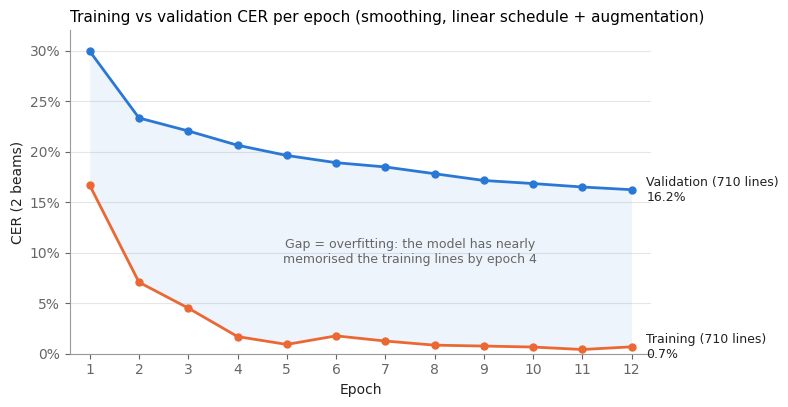

In [8]:
# Figure 1 - overfitting: run E, training-sample CER vs validation CER per epoch
curve = {}
for h in trainer_log(AUG_YES):
    for split in ['validation', 'train_sample']:
        if f'eval_{split}_cer' in h:
            curve.setdefault(int(round(h['epoch'])), {})[split] = h[f'eval_{split}_cer']
curve = pd.DataFrame(curve).T.sort_index()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.fill_between(curve.index, curve['train_sample'], curve['validation'], color=BLUE, alpha=0.08, lw=0)
ax.plot(curve.index, curve['validation'], color=BLUE, lw=2, marker='o', ms=5)
ax.plot(curve.index, curve['train_sample'], color=ORANGE, lw=2, marker='o', ms=5)
last = curve.index[-1]
ax.text(last + 0.3, curve['validation'].iloc[-1], f"Validation (710 lines)\n{curve['validation'].iloc[-1]:.1%}",
        va='center', color=INK, fontsize=9)
ax.text(last + 0.3, curve['train_sample'].iloc[-1], f"Training (710 lines)\n{curve['train_sample'].iloc[-1]:.1%}",
        va='center', color=INK, fontsize=9)
ax.text(7.5, 0.09, 'Gap = overfitting: the model has nearly\nmemorised the training lines by epoch 4', ha='center',
        fontsize=9, color=MUTED)
ax.set(xlim=(0.6, last + 0.4), ylim=(0, 0.32), xlabel='Epoch', ylabel='CER (2 beams)')
ax.set_xticks(curve.index)
ax.yaxis.set_major_formatter(PCT0)
grid(ax)
ax.set_title('Training vs validation CER per epoch (smoothing, linear schedule + augmentation)', fontsize=11, loc='left')
fig.savefig(FIGS / 'overfitting_train_vs_validation.png', dpi=200, bbox_inches='tight')
plt.show()

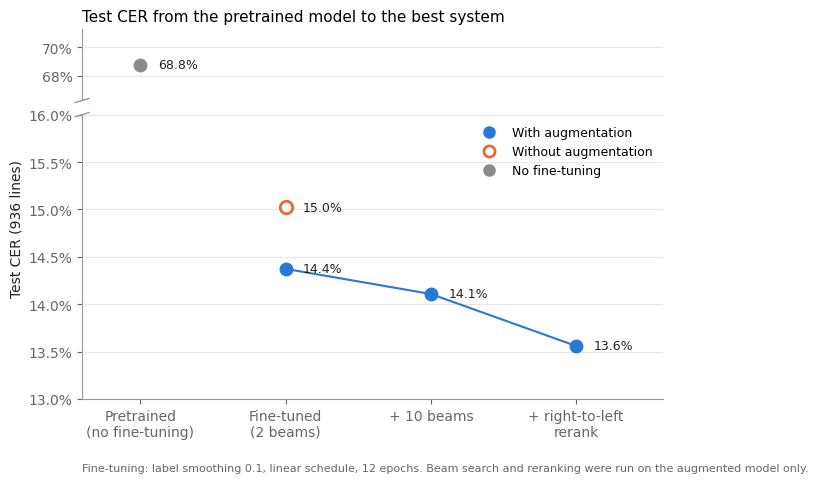

In [9]:
# Figure 2 - from the pretrained model to the best system (test CER)
stages = ['Fine-tuned\n(2 beams)', '+ 10 beams', '+ right-to-left\nrerank']
aug = [metrics.loc[(AUG_YES, d), 'test CER'] for d in ['2 beams', '10 beams', BEST_DECODING]]
noaug = {0: metrics.loc[(AUG_NO, '2 beams'), 'test CER']}
pre = pretrained['test CER']
xs = [1, 2, 3]
fig, (top, ax) = plt.subplots(2, 1, figsize=(7.5, 4.8), sharex=True, gridspec_kw={'height_ratios': [1, 4], 'hspace': 0.08})
top.plot([0], [pre], 'o', color=GRAY, ms=9)
top.text(0.12, pre, f'{pre:.1%}', va='center', color=INK, fontsize=9)
top.set_ylim(pre - 0.025, pre + 0.025)
top.yaxis.set_major_locator(plt.MultipleLocator(0.02))
top.yaxis.set_major_formatter(PCT0)
top.spines['bottom'].set_visible(False)
top.tick_params(bottom=False)
ax.plot(xs, aug, color=BLUE, lw=1.5, zorder=1)
ax.plot(xs, aug, 'o', color=BLUE, ms=9, zorder=3)
for x, v in zip(xs, aug):
    ax.text(x + 0.12, v, f'{v:.1%}', va='center', color=INK, fontsize=9)
for i, v in noaug.items():
    ax.plot([xs[i]], [v], 'o', ms=9, mfc='white', mec=ORANGE, mew=2, zorder=3)
    ax.text(xs[i] + 0.12, v, f'{v:.1%}', va='center', color=INK, fontsize=9)
low, high = min(aug + list(noaug.values())), max(aug + list(noaug.values()))
ax.set_ylim(np.floor(low * 200 - 1) / 200, np.ceil(high * 200 + 1) / 200)
ax.yaxis.set_major_formatter(PCT1)
ax.spines['top'].set_visible(False)
grid(top), grid(ax)
broken_marks(top, ax)
ax.set_xticks([0] + xs, ['Pretrained\n(no fine-tuning)'] + stages)
ax.set_xlim(-0.4, 3.6)
ax.set_ylabel('Test CER (936 lines)')
ax.yaxis.set_label_coords(-0.1, 0.6)
top.set_title('Test CER from the pretrained model to the best system', fontsize=11, loc='left')
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=BLUE, ms=8, label='With augmentation'),
                   Line2D([], [], marker='o', ls='', mfc='white', mec=ORANGE, mew=2, ms=8, label='Without augmentation'),
                   Line2D([], [], marker='o', ls='', color=GRAY, ms=8, label='No fine-tuning')],
          frameon=False, fontsize=9, loc='upper right')
fig.text(0.125, -0.04, 'Fine-tuning: label smoothing 0.1, linear schedule, 12 epochs. '
         'Beam search and reranking were run on the augmented model only.', fontsize=8, color=MUTED)
fig.savefig(FIGS / 'progress_pretrained_to_best.png', dpi=200, bbox_inches='tight')
plt.show()

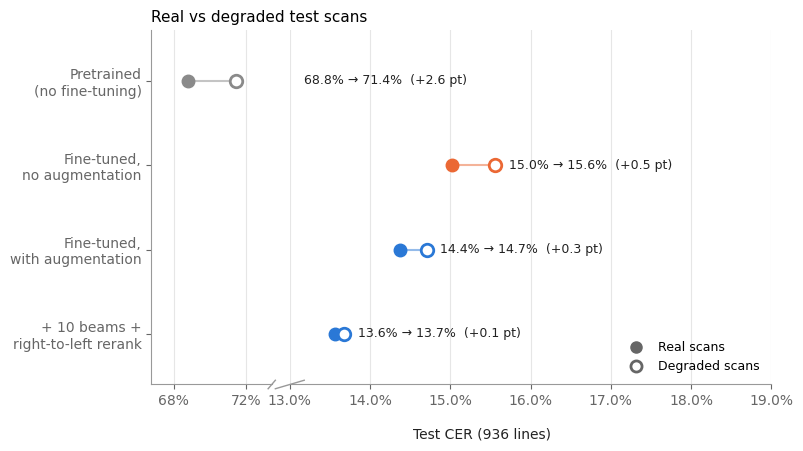

In [10]:
# Figure 3 - real vs degraded test scans (filled = real, hollow = degraded), broken x axis for the pretrained model
ROWS = [('Pretrained (no fine-tuning)', 'Pretrained\n(no fine-tuning)', GRAY),
        (AUG_NO, 'Fine-tuned,\nno augmentation', ORANGE),
        (AUG_YES, 'Fine-tuned,\nwith augmentation', BLUE),
        (BEST, '+ 10 beams +\nright-to-left rerank', BLUE)]
ROWS = [r for r in ROWS if r[0] in degraded_table.index]
if len(ROWS) < 2:
    print('Degraded predictions are missing (Part 2 needs the GPU and the models): figure 3 not drawn.')
else:
    y = np.arange(len(ROWS))[::-1]
    fig, (left, right) = plt.subplots(1, 2, figsize=(8, 0.75 * len(ROWS) + 1.6), sharey=True,
                                      gridspec_kw={'width_ratios': [1, 4], 'wspace': 0.06})
    pre_vals = degraded_table.loc['Pretrained (no fine-tuning)', ['test CER', 'test_degraded CER']]
    left.set_xlim(pre_vals.min() - 0.02, pre_vals.max() + 0.02)
    left.xaxis.set_major_locator(plt.MultipleLocator(0.04))
    rest = degraded_table.drop('Pretrained (no fine-tuning)')[['test CER', 'test_degraded CER']]
    right.set_xlim(np.floor(rest.values.min() * 200 - 1) / 200, np.ceil(rest.values.max() * 200 + 4) / 200)
    for yi, (name, label, color) in zip(y, ROWS):
        real, deg = degraded_table.loc[name, ['test CER', 'test_degraded CER']]
        pre_row = name.startswith('Pretrained')
        ax = left if pre_row else right
        ax.plot([real, deg], [yi, yi], color=color, lw=1.5, alpha=0.5, zorder=1)
        ax.plot([real], [yi], 'o', color=color, ms=9, zorder=3)
        ax.plot([deg], [yi], 'o', mfc='white', mec=color, mew=2, ms=9, zorder=3)
        # the pretrained label goes at the start of the right panel, past the axis break
        anchor = (right.get_xlim()[0], yi) if pre_row else (max(real, deg), yi)
        right.annotate(f'{real:.1%} → {deg:.1%}  ({100 * (deg - real):+.1f} pt)', anchor, xytext=(10, 0),
                       textcoords='offset points', va='center', fontsize=9, color=INK)
    left.xaxis.set_major_formatter(PCT0)
    right.xaxis.set_major_formatter(PCT1)
    right.spines['left'].set_visible(False)
    right.tick_params(left=False)
    broken_marks(left, right, vertical=False)
    left.set_yticks(y, [r[1] for r in ROWS])
    for ax in (left, right):
        grid(ax, 'x')
        ax.set_ylim(y.min() - 0.6, y.max() + 0.6)
    right.set_xlabel('Test CER (936 lines)')
    right.xaxis.set_label_coords(0.4, -0.12)
    left.set_title('Real vs degraded test scans', fontsize=11, loc='left')
    right.legend(handles=[Line2D([], [], marker='o', ls='', color=MUTED, ms=8, label='Real scans'),
                          Line2D([], [], marker='o', ls='', mfc='white', mec=MUTED, mew=2, ms=8, label='Degraded scans')],
                 frameon=False, fontsize=9, loc='lower right')
    fig.savefig(FIGS / 'degraded_vs_real.png', dpi=200, bbox_inches='tight')
    plt.show()

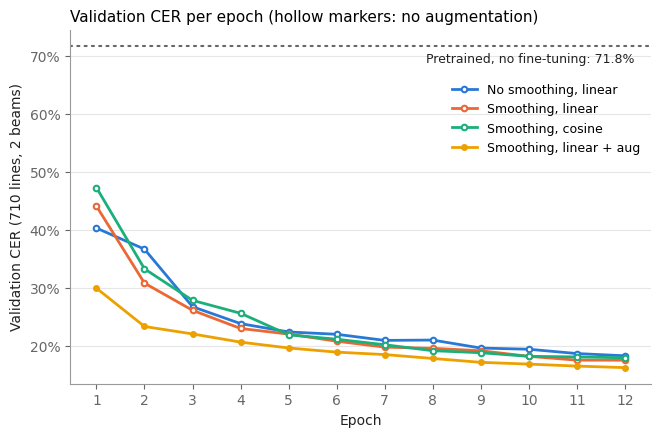

In [11]:
# Figure 4 - validation CER per epoch of every fine-tuned run, and the pretrained baseline
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for (name, info), color in zip(RUN_INFO.iterrows(), SERIES):
    log = trainer_log(name)
    key = 'eval_cer' if any('eval_cer' in h for h in log) else 'eval_validation_cer'
    ev = [(int(round(h['epoch'])), h[key]) for h in log if key in h]
    style = dict(color=color, lw=2, marker='o', ms=4)
    if not info['augmented']:
        style.update(mfc='white', mew=1.5)
    ax.plot(*zip(*ev), label=name, **style)
ax.axhline(pretrained['validation CER'], color=MUTED, lw=1.5, ls=(0, (1, 2.5)), dash_capstyle='round')
ax.text(12.2, pretrained['validation CER'] - 0.012, f"Pretrained, no fine-tuning: {pretrained['validation CER']:.1%}",
        ha='right', va='top', fontsize=9, color=INK)
ax.set(xlabel='Epoch', ylabel='Validation CER (710 lines, 2 beams)')
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(PCT0)
grid(ax)
ax.legend(frameon=False, fontsize=9, loc='upper right', bbox_to_anchor=(1, 0.88))
ax.set_title('Validation CER per epoch (hollow markers: no augmentation)', fontsize=11, loc='left')
fig.savefig(FIGS / 'validation_curves.png', dpi=200, bbox_inches='tight')
plt.show()